<a href="https://colab.research.google.com/github/mmjtech20-pixel/MLT-Practicals/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving IRIS.csv to IRIS (1).csv


In [ ]:
df = pd.read_csv('/content/IRIS (1).csv')

print(df.head())
print(df.shape)
print(df.columns)

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
(150, 5)
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')


In [ ]:
X = df.drop(columns=['species'])
y = df['species']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
y_pred = knn.predict(X_test_scaled)

print("Actual values:")
print(y_test.to_numpy())

print("Predicted values:")
print(y_pred)

Actual values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']
Predicted values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9333333333333333

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



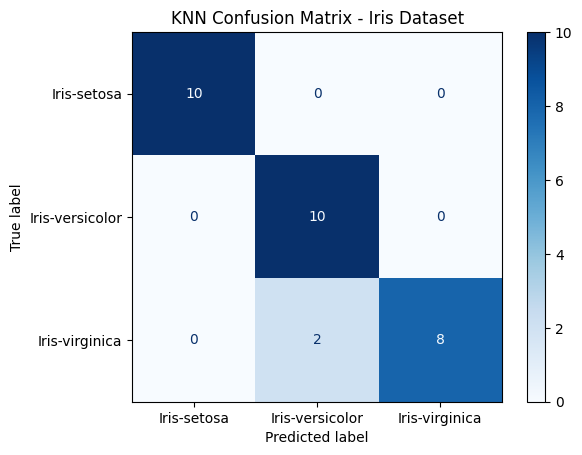

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)

plt.title("KNN Confusion Matrix - Iris Dataset")
plt.show()

In [ ]:
for k in range(1, 16):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    print(f"K = {k}, Accuracy = {accuracy_score(y_test, predictions):.4f}")

K = 1, Accuracy = 0.9667
K = 2, Accuracy = 0.9333
K = 3, Accuracy = 0.9333
K = 4, Accuracy = 0.9333
K = 5, Accuracy = 0.9333
K = 6, Accuracy = 0.9333
K = 7, Accuracy = 0.9667
K = 8, Accuracy = 0.9333
K = 9, Accuracy = 0.9667
K = 10, Accuracy = 0.9667
K = 11, Accuracy = 0.9667
K = 12, Accuracy = 0.9667
K = 13, Accuracy = 0.9667
K = 14, Accuracy = 0.9333
K = 15, Accuracy = 0.9667


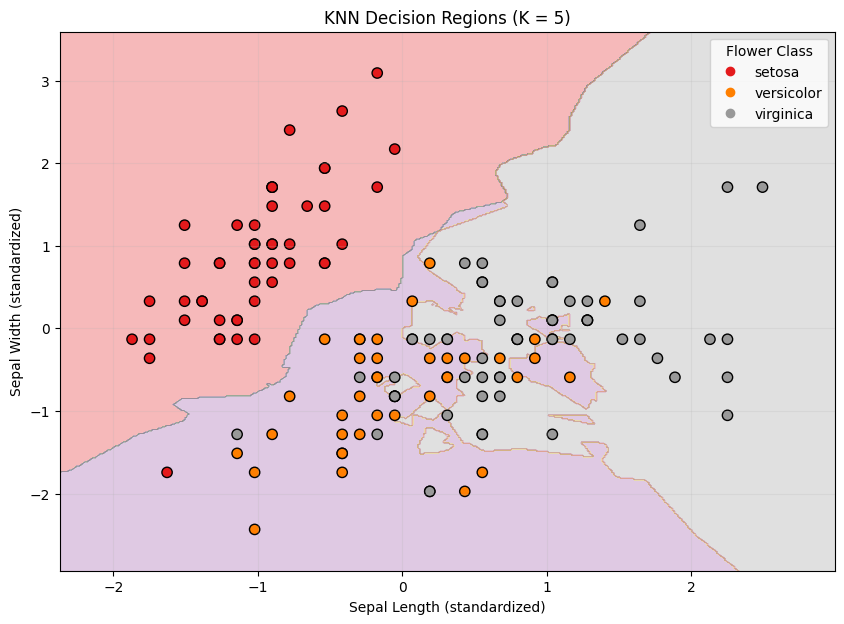

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Load Iris dataset
iris = load_iris()
X = iris.data[:, :2]  # First two features
y = iris.target

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_scaled, y)

# Create a grid for plotting decision regions
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

# Predict the class for every point in the grid
grid = np.c_[xx.ravel(), yy.ravel()]
Z = knn.predict(grid)
Z = Z.reshape(xx.shape)

# Plot colored decision regions
plt.figure(figsize=(10, 7))
plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap=plt.cm.Set1
)

# Plot actual flower samples
scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap=plt.cm.Set1,
    edgecolors='black',
    s=55
)

plt.xlabel('Sepal Length (standardized)')
plt.ylabel('Sepal Width (standardized)')
plt.title('KNN Decision Regions (K = 5)')
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names),
    title='Flower Class'
)
plt.grid(alpha=0.2)
plt.show()


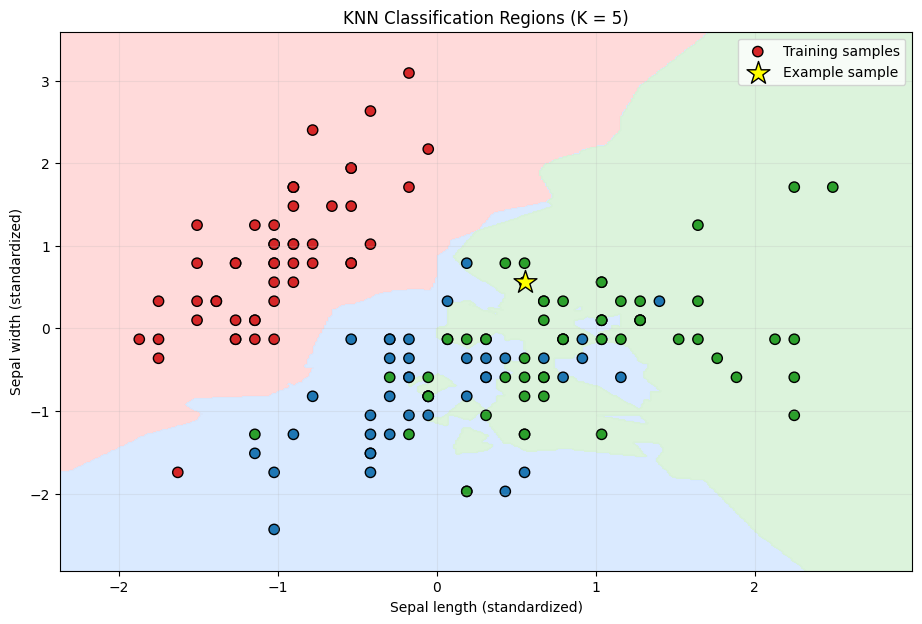

Predicted flower: virginica


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Load Iris dataset
iris = load_iris()
X = iris.data[:, :2]
y = iris.target

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train KNN
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_scaled, y)

# Create a grid of points
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

# Predict a class for every grid point
grid = np.c_[xx.ravel(), yy.ravel()]
Z = knn.predict(grid).reshape(xx.shape)

# Set colors for the three classes
region_colors = ListedColormap(['#ffd6d6', '#d6e8ff', '#d9f2d9'])
point_colors = ListedColormap(['#d62728', '#1f77b4', '#2ca02c'])

# Draw classification regions
plt.figure(figsize=(11, 7))
plt.contourf(
    xx, yy, Z,
    cmap=region_colors,
    alpha=0.9
)

# Draw the actual Iris samples
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=y,
    cmap=point_colors,
    edgecolors='black',
    s=55,
    label='Training samples'
)

# Select one sample to demonstrate prediction
query = X_scaled[[100]]
prediction = knn.predict(query)[0]

# Highlight the selected sample
plt.scatter(
    query[0, 0], query[0, 1],
    marker='*',
    s=300,
    c='yellow',
    edgecolors='black',
    label='Example sample'
)

plt.xlabel('Sepal length (standardized)')
plt.ylabel('Sepal width (standardized)')
plt.title(f'KNN Classification Regions (K = {k})')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Predicted flower:", iris.target_names[prediction])
